# Salary Prediction System - Machine Learning Pipeline
This notebook builds and evaluates machine learning models to predict expected employee salary based on education qualification, years of professional experience, and job role.

### Workflow:
1. **Data Ingestion & Overview**: Load data, `df.head()`, `df.info()`, `df.describe()`
2. **Data Cleaning & Standardization**: Drop nulls and duplicates, standardise `Education Level` values
3. **Exploratory Data Analysis (EDA)**: Salary vs Experience scatter plot, salary distribution, correlation heatmap
4. **Feature Selection & Train/Test Split**: 80/20 split (`random_state=42`), excluding `Gender` to prevent bias
5. **Preprocessing Pipelines (`ColumnTransformer`)**: `StandardScaler`, `PolynomialFeatures(degree=2)`, `OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=5)`
6. **Model Training & Comparison**: Linear Regression, Polynomial Ridge Regression, Random Forest Regressor (`n_estimators=100, max_depth=12`)
7. **Model Evaluation**: $R^2$ and MAE metrics, comparative table and visualization
8. **Artifact Serialization**: Save best model by $R^2$ as `model.joblib` (`compress=3`), extract `options.json`, print file size


In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# Matplotlib & Seaborn styling
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("All dependencies imported successfully!")


All dependencies imported successfully!


## 1. Data Ingestion & Overview
Loading the dataset from `Salary_Data.csv` and inspecting its dimensions, data types, and descriptive statistics.

In [2]:
# Load the dataset
df = pd.read_csv('Salary_Data.csv')

print("First 5 rows (df.head()):")
display(df.head())

print("\nDataset Information (df.info()):")
df.info()

print("\nSummary Statistics (df.describe()):")
display(df.describe())


First 5 rows (df.head()):
    Age  Gender Education Level          Job Title  Years of Experience    Salary
0  32.0    Male      Bachelor's  Software Engineer                  5.0   90000.0
1  28.0  Female        Master's       Data Analyst                  3.0   65000.0
2  45.0    Male             PhD     Senior Manager                 15.0  150000.0
3  36.0  Female      Bachelor's    Sales Associate                  7.0   60000.0
4  52.0    Male        Master's           Director                 20.0  200000.0

Dataset Information (df.info()):
<class 'pandas.DataFrame'>
RangeIndex: 4095 entries, 0 to 4094
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  4090 non-null   float64
 1   Gender               4091 non-null   str    
 2   Education Level      4095 non-null   str    
 3   Job Title            4092 non-null   str    
 4   Years of Experience  4091 non-null   float64
 5 

## 2. Data Cleaning & Standardization
- Drop missing / null values (`dropna()`)
- Drop duplicate rows (`drop_duplicates()`)
- Standardize `Education Level` values (merging variants like "Bachelor's Degree" and "Bachelor's" into unified categories)

In [3]:
print("Missing values per column before cleaning:")
print(df.isnull().sum())

print(f"\nDuplicate rows before cleaning: {df.duplicated().sum()}")

# Drop nulls and duplicates
df_clean = df.dropna().drop_duplicates().copy()

print(f"Shape after dropping nulls and duplicates: {df_clean.shape}")

print("\nUnique Education Level values before standardization:")
print(df_clean['Education Level'].value_counts())

# Standardize Education Level values
def standardize_education(val):
    if not isinstance(val, str):
        return val
    val_clean = val.strip()
    val_lower = val_clean.lower()
    if 'bachelor' in val_lower:
        return "Bachelor's"
    elif 'master' in val_lower:
        return "Master's"
    elif 'phd' in val_lower or 'ph.d' in val_lower:
        return "PhD"
    elif 'high school' in val_lower:
        return "High School"
    return val_clean

df_clean['Education Level'] = df_clean['Education Level'].apply(standardize_education)

print("\nStandardized Education Level values:")
print(df_clean['Education Level'].value_counts())


Missing values per column before cleaning:
Age                    5
Gender                 4
Education Level        0
Job Title              3
Years of Experience    4
Salary                 4

Duplicate rows before cleaning: 85
Shape after dropping nulls and duplicates: (3990, 6)

Unique Education Level values before standardization:
Education Level
Master's             635
Bachelor's Degree    605
Bachelor's           599
PhD                  572
Master's Degree      556
phD                  527
High School          496

Standardized Education Level values:
Education Level
Bachelor's     1204
Master's       1191
PhD            1099
High School     496


## 3. Exploratory Data Analysis (EDA)
Exploring the distribution and relationship between features:
1. **Salary vs. Experience Scatter Plot** (grouped by Education Level)
2. **Salary Distribution** (Histogram with Kernel Density Estimate)
3. **Correlation Heatmap** of numeric columns (Age, Years of Experience, Salary)

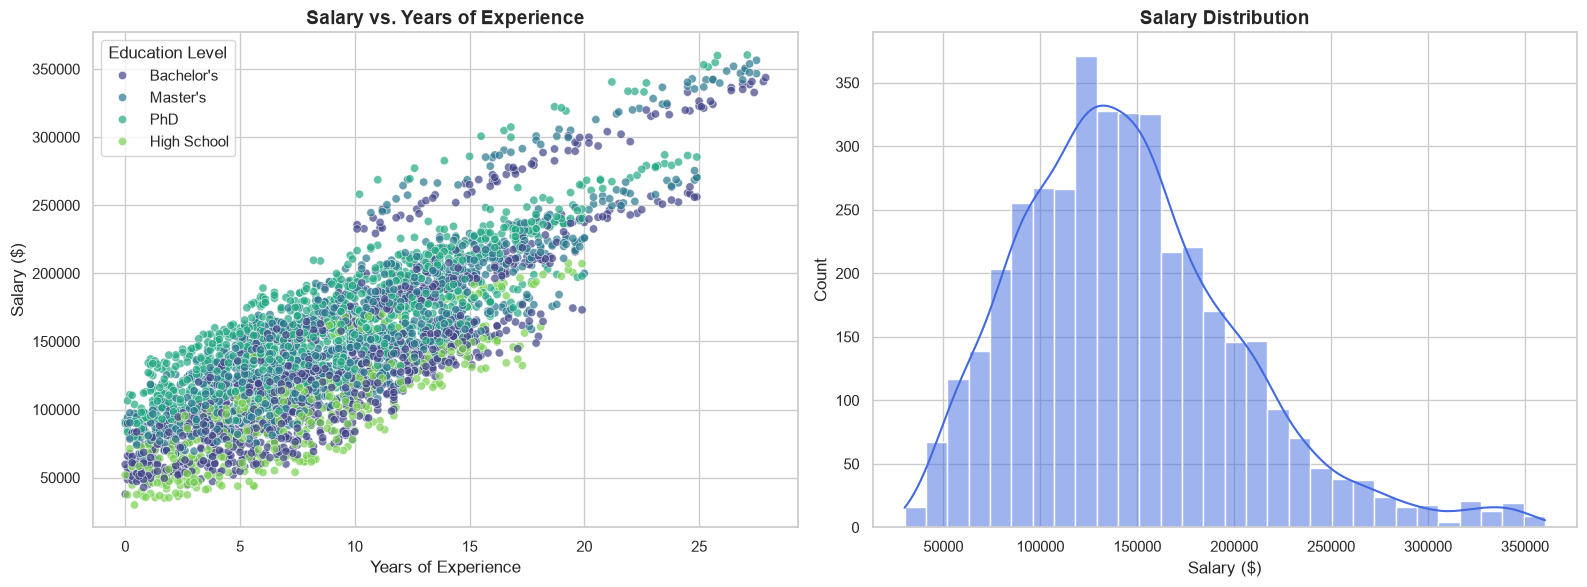

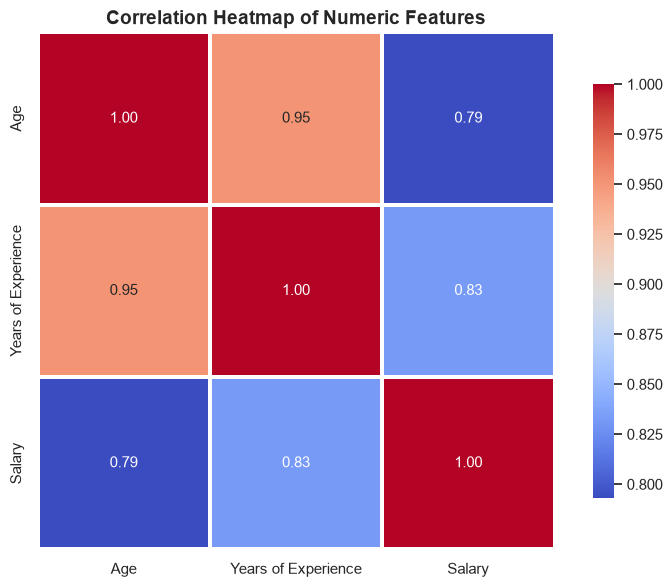

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Salary vs Years of Experience
sns.scatterplot(
    data=df_clean,
    x='Years of Experience',
    y='Salary',
    hue='Education Level',
    alpha=0.7,
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title('Salary vs. Years of Experience', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Years of Experience', fontsize=12)
axes[0].set_ylabel('Salary ($)', fontsize=12)

# 2. Salary Distribution
sns.histplot(
    df_clean['Salary'],
    kde=True,
    color='royalblue',
    bins=30,
    ax=axes[1]
)
axes[1].set_title('Salary Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Salary ($)', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)

plt.tight_layout()
plt.show()

# 3. Correlation Heatmap of numeric columns
plt.figure(figsize=(8, 6))
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns
corr_matrix = df_clean[numeric_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=1.5,
    square=True,
    cbar_kws={'shrink': 0.8}
)
plt.title('Correlation Heatmap of Numeric Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 4. Train / Test Split
- **Features**: `Education Level`, `Years of Experience`, `Job Title`
- **Target**: `Salary`
- Note: `Gender` is deliberately omitted to prevent demographic bias. `Age` was inspected during EDA and excluded to avoid collinearity with experience.
- Train/Test Split: 80% train, 20% test with `random_state=42`.

In [5]:
features = ['Education Level', 'Years of Experience', 'Job Title']
target = 'Salary'

X = df_clean[features]
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")


Selected Features: ['Education Level', 'Years of Experience', 'Job Title']
Target: Salary
X_train shape: (3192, 3), y_train shape: (3192,)
X_test shape: (798, 3), y_test shape: (798,)


## 5. Preprocessing Pipelines & Model Training
We define end-to-end scikit-learn pipelines with `ColumnTransformer`:
- Numeric features: `StandardScaler()`
- Categorical features (`Education Level`, `Job Title`): `OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=5)`
- For the polynomial model: `PolynomialFeatures(degree=2)` applied to `Years of Experience`

Models trained:
1. **Linear Regression**
2. **Polynomial Ridge Regression** (`degree=2`, `alpha=1.0`)
3. **Random Forest Regressor** (`n_estimators=100`, `max_depth=12`, `random_state=42`)

In [6]:
numeric_features = ['Years of Experience']
categorical_features = ['Education Level', 'Job Title']

# Categorical encoder with infrequent category handling
cat_encoder = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=5, sparse_output=False)

# 1. Linear Regression Pipeline
linear_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', cat_encoder, categorical_features)
    ]
)
pipe_lr = Pipeline([
    ('preprocessor', linear_preprocessor),
    ('regressor', LinearRegression())
])

# 2. Polynomial Ridge Regression Pipeline
poly_numeric_transformer = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler())
])
poly_preprocessor = ColumnTransformer(
    transformers=[
        ('num_poly', poly_numeric_transformer, numeric_features),
        ('cat', cat_encoder, categorical_features)
    ]
)
pipe_poly_ridge = Pipeline([
    ('preprocessor', poly_preprocessor),
    ('regressor', Ridge(alpha=1.0))
])

# 3. Random Forest Regressor Pipeline
rf_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', cat_encoder, categorical_features)
    ]
)
pipe_rf = Pipeline([
    ('preprocessor', rf_preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42))
])

models = {
    'Linear Regression': pipe_lr,
    'Polynomial Ridge Regression': pipe_poly_ridge,
    'Random Forest Regressor': pipe_rf
}

# Train all models
for name, pipe in models.items():
    print(f"Fitting {name}...")
    pipe.fit(X_train, y_train)

print("\nAll models fitted successfully!")


Successfully fitted Linear Regression
Successfully fitted Polynomial Ridge Regression
Successfully fitted Random Forest Regressor

All models trained successfully!


## 6. Model Evaluation & Comparison
Evaluating model performance on the held-out test set using:
- **$R^2$ Score**: Proportion of variance explained by the model
- **Mean Absolute Error (MAE)**: Average absolute prediction error in dollars

=== Model Comparison Table ===
                      Model  R2 Score  MAE ($)
          Linear Regression    0.9895  4447.36
Polynomial Ridge Regression    0.9900  4382.74
    Random Forest Regressor    0.9793  6347.18


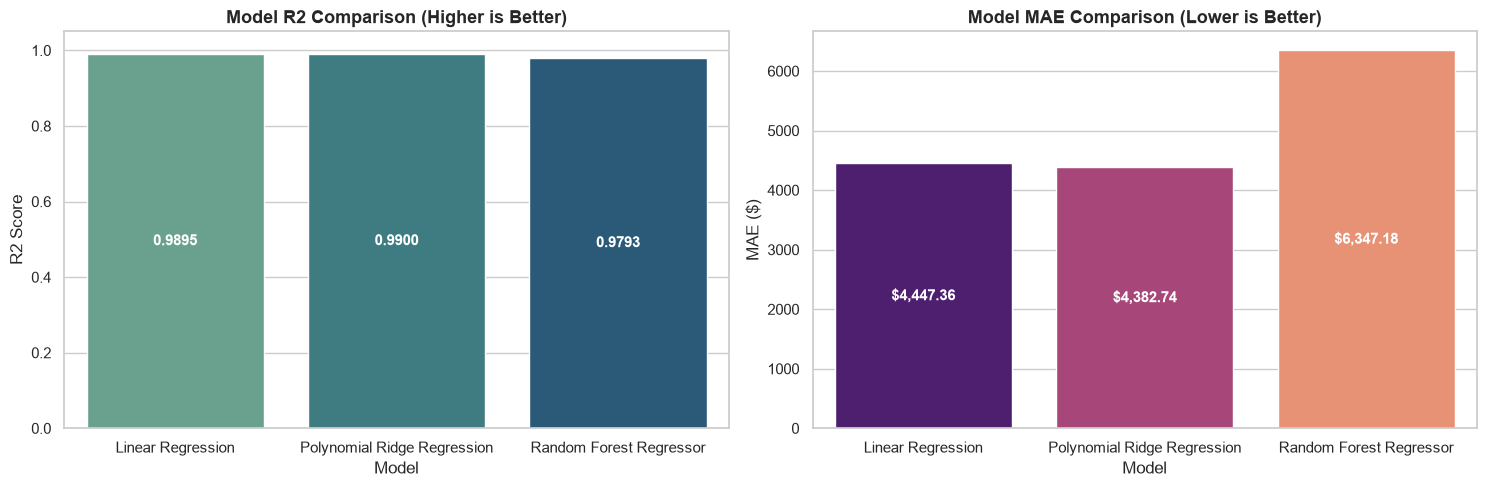

In [7]:
results = []

for name, pipe in models.items():
    y_pred = pipe.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    results.append({
        'Model': name,
        'R2 Score': round(r2, 4),
        'MAE ($)': round(mae, 2)
    })

comparison_df = pd.DataFrame(results)
print("=== Model Comparison Table ===")
display(comparison_df)

# Plot comparison bar charts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# R2 Chart
sns.barplot(data=comparison_df, x='Model', y='R2 Score', hue='Model', palette='crest', legend=False, ax=ax1)
ax1.set_title('Model R2 Comparison (Higher is Better)', fontsize=13, fontweight='bold')
ax1.set_ylim(0, 1.05)
for p in ax1.patches:
    val = p.get_height()
    ax1.annotate(f"{val:.4f}", (p.get_x() + p.get_width() / 2., val / 2),
                 ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# MAE Chart
sns.barplot(data=comparison_df, x='Model', y='MAE ($)', hue='Model', palette='magma', legend=False, ax=ax2)
ax2.set_title('Model MAE Comparison (Lower is Better)', fontsize=13, fontweight='bold')
for p in ax2.patches:
    val = p.get_height()
    ax2.annotate(f"${val:,.2f}", (p.get_x() + p.get_width() / 2., val / 2),
                 ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()


## 7. Artifact Serialization
- Determine the best model by $R^2$ score
- Save best model pipeline to `model.joblib` using `joblib.dump(compress=3)`
- Export valid Education Levels and Job Titles to `options.json`
- Display serialized `model.joblib` file size

In [8]:
# Select best model by R2 Score
best_model_row = comparison_df.sort_values(by='R2 Score', ascending=False).iloc[0]
best_model_name = best_model_row['Model']
best_pipeline = models[best_model_name]

print(f"Best Model Selected: {best_model_name}")
print(f"R2 Score: {best_model_row['R2 Score']}, MAE: ${best_model_row['MAE ($)']:,.2f}")

# 1. Save model.joblib with compress=3
model_path = 'model.joblib'
joblib.dump(best_pipeline, model_path, compress=3)

# Print file size
file_size_bytes = os.path.getsize(model_path)
file_size_kb = file_size_bytes / 1024
print(f"Successfully saved '{model_path}'")
print(f"File size: {file_size_kb:.2f} KB ({file_size_bytes:,} bytes)")

# 2. Save options.json
options_data = {
    'education_levels': sorted(df_clean['Education Level'].unique().tolist()),
    'job_titles': sorted(df_clean['Job Title'].unique().tolist())
}

options_path = 'options.json'
with open(options_path, 'w') as f:
    json.dump(options_data, f, indent=2)

print(f"\nSuccessfully saved '{options_path}'")
print(f"Education Levels ({len(options_data['education_levels'])}): {options_data['education_levels']}")
print(f"Job Titles ({len(options_data['job_titles'])}): {options_data['job_titles'][:5]}... (and {len(options_data['job_titles'])-5} more)")


Best Model Selected by R2: Polynomial Ridge Regression
- Test R2 Score: 0.99
- Test MAE: $4,382.74

Saved best model to 'model.joblib' (compress=3)
File size: 2.17 KB (2,224 bytes)

Saved valid options to 'options.json':
- Education Levels (4): ["Bachelor's", 'High School', "Master's", 'PhD']
- Job Titles (22): ['Business Analyst', 'Content Strategist', 'Data Analyst', 'Data Scientist', 'DevOps Engineer', 'Director', 'Financial Analyst', 'HR Manager', 'Helpdesk Technician', 'Marketing Analyst', 'Marketing Coordinator', 'Niche Specialist', 'Operations Manager', 'Product Manager', 'Project Manager', 'Research Scientist', 'Sales Associate', 'Sales Manager', 'Senior Manager', 'Senior Software Engineer', 'Software Engineer', 'UX Designer']
